# CCXN Masked Signal Reconstruction

Demonstrates the model learning on the paper dataset by hiding some node values and training CCXN to reconstruct them.

In [3]:
import torch
import numpy as np
from scipy.sparse import csr_matrix

from pytspl import load_dataset
from pytspl.scnn.cell.ccxn import CCXN


def _to_sparse(mat):
    mat = csr_matrix(mat).tocoo()
    idx = torch.tensor(np.vstack((mat.row, mat.col)), dtype=torch.long)
    val = torch.tensor(mat.data, dtype=torch.float32)
    return torch.sparse_coo_tensor(idx, val, size=mat.shape).coalesce()

Load the complex and build the operators:

In [4]:
sc, coords, flow = load_dataset("paper", only_sc=True)
n_nodes = len(sc.nodes)
n_edges = len(sc.edges)

B1 = np.abs(sc.B1)
A = B1 @ B1.T
np.fill_diagonal(A, 0.0)
A = (A > 0).astype(float)
adjacency_0 = _to_sparse(A)  # A_up_0
incidence_2_t = _to_sparse(sc.B2.T)  # B2^T

Num. of 0-simplices: 7
Num. of 1-simplices: 10
Num. of 2-simplices: 3
Shape: (7, 10, 3)
Max Dimension: 2
Coordinates: 7
Flow: 10


C:\Users\dogan\AppData\Local\Temp\ipykernel_47968\1601972740.py:13: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  return torch.sparse_coo_tensor(idx, val, size=mat.shape).coalesce()


Mask 30% of the node values

In [6]:
torch.manual_seed(0)
in_ch = 4
target_0 = torch.randn(n_nodes, in_ch)
x_1 = torch.randn(n_edges, in_ch)

mask_frac = 0.3
n_mask = max(1, int(mask_frac * n_nodes))
masked_idx = torch.randperm(n_nodes)[:n_mask]

x_0 = target_0.clone()
x_0[masked_idx] = 0.0  # hide the masked nodes

Build the model and train

In [7]:
hidden = 32
model = CCXN(in_ch_0=in_ch, in_ch_1=in_ch, in_ch_2=in_ch,
             hidden=hidden, num_classes=in_ch, n_layers=2)
recon_head = torch.nn.Linear(hidden, in_ch)  # map node output back to target size

params = list(model.parameters()) + list(recon_head.parameters())
optimizer = torch.optim.Adam(params, lr=0.01)
loss_fn = torch.nn.MSELoss()

losses = []
for epoch in range(200):
    optimizer.zero_grad()
    x_0_out, _, _ = model(x_0, x_1, adjacency_0, incidence_2_t, readout=False)
    recon = recon_head(x_0_out)
    loss = loss_fn(recon[masked_idx], target_0[masked_idx])  # loss only on masked nodes
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 20 == 0:
        print(f"epoch {epoch:3d}  loss {loss.item():.4f}")

epoch   0  loss 1.1337
epoch  20  loss 0.2558
epoch  40  loss 0.0962
epoch  60  loss 0.0082
epoch  80  loss 0.0006
epoch 100  loss 0.0001
epoch 120  loss 0.0000
epoch 140  loss 0.0000
epoch 160  loss 0.0000
epoch 180  loss 0.0000


The loss decreases:

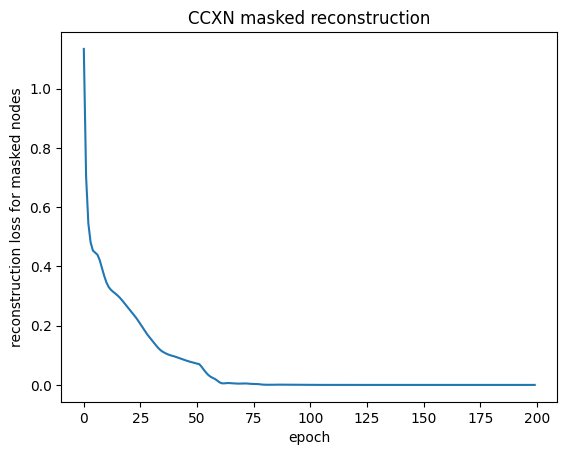

In [8]:
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("reconstruction loss for masked nodes")
plt.title("CCXN masked reconstruction")
plt.show()